In [1]:
import sys, time, tempfile
from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next(c for c in [_p, *_p.parents] if (c / 'C' / 'evoca.h').is_file())
sys.path.insert(0, str(ROOT / 'python'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import evoca_explore as ee
from evoca_py import import_run

WS = 'Resource-driving'
NB_T0 = time.time()
TMP_RUNS = tempfile.mkdtemp(prefix='rd_runs_')   # scratch recipes; never litter Runs/
print('repo root:', ROOT)

repo root: /Users/n/Projects/EvoCA


# Resource-driving: lab notebook

**Question.** Does evolvability peak at *intermediate* resource driving (an inverted U), and is the true
control axis the gradient steepness `food_inc / tax` (with the per-capita dissipation throughput
Phi as the physical x-axis) rather than `food_inc` alone?

Chronological lab notebook (newest section at the bottom). Finished campaign write-ups live in
[`digests/viability-brackets.ipynb`](digests/viability-brackets.ipynb) (R1, draft digest) and
[`digests/resource-driving-inverted-U.ipynb`](digests/resource-driving-inverted-U.ipynb) (skeleton;
no sweep run yet). Raw scan data: [`Scans/2026-05-18_R1_mscale_bracket/`](Scans/2026-05-18_R1_mscale_bracket/notes.md).
Open questions and next directions are in `ISSUES.md` (shown next).

*Snapshot of `ISSUES.md` as of the last execution of this notebook. `ISSUES.md` is the single source of
truth; edit it there, not here.*

In [2]:
display(Markdown((ROOT / 'Research' / WS / 'ISSUES.md').read_text()))

# Resource-driving: issues and directions
_Updated 2026-10-15_

## Decisions needed (N)
- **RES-D1**: Gate for the Tier-2 branch `resource-driving` (C1 `food_per`; C2/L2 float `env_mask` and spatial gradient niches follow on the same branch) — options: (a) review in the /tmp worktree with a pre-merge test notebook and bit-for-bit parity at `food_per=1`, then merge; (b) leave on the branch until RES-N1 shows the high-resource flank needs richer structure to be rescued. Recommendation: do RES-N1 on `main` now (needs no branch code), and review the branch in parallel, since C3 and every spatial-niche experiment are blocked on it. Blocks: RES-N5 (C3), RES-N6 (C2/L2). Source: `Docs/Oct2026/00-review-of-prompt1.md`, board W1-d.
- **RES-D2**: Evolution arms for the RES-N1 campaign — options: (a) LUT-only (`mu_egene = mu_egenome = 0`), where `A_new` is well posed; (b) joint LUT + egene as in R1 and the checkpoint's two "exception" hypotheses, where `A_new` is not well posed (RES-Q3) and only the fixed-space `eg_excess` / `dyn_excess` and eff-activity are interpretable; (c) both as separate arms. Recommendation: (c), with (a) as the primary inverted-U figure. Blocks: RES-N1 design freeze.

## Open questions
- **RES-Q1**: Is the high-resource flank a drift regime (raw diversity high, excess near zero), as checkpoint section B predicts? R1 never sampled `food_inc` above 0.018, so the high half of the inverted U is untested at campaign scale. The 2026-10-15 pilot (1 seed, `tax` 0.035, LUT-only, N=128, 3000 steps; notebook final section) shows `A_new` rising, peaking in the interior and collapsing at `food_inc/tax` about 2.9 while raw distinct-genome count saturates — suggestive only, and confounded by occupancy (below ratio 1 more cells means more genomes; judge excess per capita or against a population-matched baseline). Source: `Docs/checkpoint 3 July 2026.md` section B; notebook pilot.
- **RES-Q2**: Does per-capita throughput Phi carry information beyond `food_inc/tax`? In the pilot, Phi sits at about `tax` whenever the population is food-limited and nothing overflows, and rises toward `food_inc` only on the overflow-dominated rich flank, so as an x-axis it is nearly degenerate across the viable interior. This follows from the L1 energy identity: at quasi-steady state Phi = max(`tax`, `food_inc`), and below ratio 1 the final alive density equals `food_inc/tax` (0.403, 0.600, 0.897 vs 0.4, 0.6, 0.9 in the pilot), so the ratio is also the carrying occupancy. Test: Phi vs the ratio across `tax` levels in RES-N1; also try total throughput per cell and Phi restricted to cells with positive mouthful.
- **RES-Q3**: `A_new` (G1) is built on the LUT-hash Channon shadow, which models LUT bytes only, while the activity hash covers the full genome. Per the recorded `shadow-models-lut-only-mismatch` finding (and `Docs/EvoCA_research_directions.md` section 2), excess metrics are not well posed when egenes evolve. Is `A_new` interpretable in the joint LUT + egene arm? Needs either an egene-aware shadow for `A_new`, or restriction to LUT-only arms. Do not interpret `A_new` from R1-style joint runs.
- **RES-Q4**: Does the viability threshold and the productive peak collapse onto `food_inc/tax`? Weak hint in existing R1 rows: ordering extinction by the ratio has AUC 0.863 vs 0.839 by `food_inc` alone, and at `food_inc` 0.013 extinction is 0% at `tax` 0.030/0.035 but 30% at 0.040 (`m_scale` and mutation axes pooled, so confounded). R1's `tax` range (0.030 to 0.040, a 33% span) is far too narrow for a real collapse test. Source: `Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/results.csv`, notebook R1 section.
- **RES-Q5**: R1 viability was U-shaped in `m_scale` (worst at intermediate under scarcity). Since intake is `(m/25) * matches * F`, is the real control axis closer to `food_inc * m_scale / tax` than `food_inc / tax`? This is a hypothesis from the intake formula, not a finding; RES-N1 should cross `m_scale` with the ratio to test it.
- **RES-Q6**: Are N's two "exceptions" real: does egenome (cognitive load) or LUT eating-speed evolution persist at high resource (checkpoint prompt; section B)? The falsifying outcome (cognitive load still rising at high `food_inc`) would be the more interesting result. Readouts: `cog_load`, per-lineage net metabolic return (D2, merged).
- **RES-Q7**: R1's "low `mu_lut` wins" is conditional on `m_scale` <= 2.5 (optimum shifts high when `m_scale` is bracketed up). Does the mutation optimum also depend on the ratio? Fold into RES-N1 as a `mu_lut` axis at two levels.

## Next directions
- **RES-N1**: Full inverted-U campaign (the section-B figure, checkpoint B1/LB2), unblocked by the 2026-10-15 merges of L1 and G1 — campaign, no blocker (uses `run_sim` as is). Spec: x-axis `food_inc/tax`, log-spaced about 10 points over 0.25 to 4 (denser at 0.25 to 0.8 where the pilot shows a sharp viability threshold, and extending well past R1's 0.018); `tax` at three levels spanning at least a factor of 5 (for example 0.01, 0.035, 0.07) so the collapse is a real test; `m_scale` at {2.5, 3.5}; `mu_lut` at {0.03, 0.15}; three seeds; N=256, 8000 steps (pilot at N=128/3000 steps shows the activity metrics still growing); arms per RES-D2. Record: `extinct`, `final_pop`, `a_new_final/slope`, `dyn_excess_pc_slope`, `eg_excess_pc_slope`, `n_distinct_genomes_mean`, `cog_load_mean`, `diss_phi_mean/_final`, `diss_tax/death/overflow_step_mean`. Size: about 10 x 3 x 2 x 2 x 3 = 360 runs per arm (R1: 300 runs in 743 s on 32 cores). Falsification criteria: (i) curves at different `tax` superimpose against the ratio but not against `food_inc`; (ii) raw diversity flat/rising on the high flank while `A_new` and `dyn_excess` fall; (iii) if `A_new` or `cog_load` keeps rising at high ratio, the flat-landscape claim is falsified. Cross-ref: B1, B2, L1, G1, C-none.
- **RES-N2**: Promote `digests/resource-driving-inverted-U.ipynb` from skeleton to a result digest after RES-N1: raw vs excess overlay against the ratio and against Phi, 0.013 window marked, markers encode other scan params (LB2); add the adaptive-fraction readout `excess/raw` (B2). Kind: analysis; blocked on RES-N1.
- **RES-N3**: Adaptive-vs-drift test on the RES-N1 sweep (H1): lineage net return (D2, merged) plus `A_new` plus shadow-beating test at starved/intermediate/rich ratios. Kind: analysis; cross-workstream with Lineage-co-evolution and Activity-metrics; blocked on RES-N1.
- **RES-N4**: Add Phi and the dissipation breakdown to the interactive `ts` probe (it currently logs `t,pop,F_env,f_priv,lut_div,eg_ent,activity_flux`; no dissipation column) so a run can be watched crossing from the starved to the rich flank in the SDL/notebook UI. Kind: needs dev (small, python/controls.py plus C getter already exists); no blocker.
- **RES-N5**: C3 campaign: does temporal lumpiness of the food field create evolutionary opportunity? With `food_per` > 1 (C1), hold mean `F_env` fixed while raising its temporal/spatial variance and test whether excess activity rises at the *rich* ratio, where uniform regeneration gives drift. Prediction and negative-result reading in checkpoint section C. Kind: campaign; blocked on RES-D1 (branch merge).
- **RES-N6**: C2/L2: float `env_mask` ceiling plus relaxation toward the mask (LB3 option (a)), and a spatial source/sink gradient; test whether a more efficient lineage extends the viable distance from the source (checkpoint section L item 2). Kind: needs dev (same branch as C1); blocked on RES-D1.
- **RES-N7**: Localize the viability threshold `ratio_crit(tax)` by bisection at several `tax` levels (the pilot shows extinction-to-viable between ratio 0.3 and 0.4 at `tax` 0.035; near-threshold runs are highly sensitive to the random stream: in the pilot the same seed gave 21 cells inside `run_sim` and 255 when the identical configuration was stepped by hand, because the per-sample activity/shadow updates consume the C PRNG; use replicate seeds and report the extinction fraction). It is the cheapest direct test of the ratio hypothesis (RES-Q4). Kind: campaign (small); no blocker.

## Parked
- Food + waste model (checkpoint LB6 / E2: waste with its own `W_env` field as a mechanism that keeps selection alive at abundance): belongs to the `chem` branch (Tier-2), not this workstream until chem merges.
- Motility / navigating a gradient (M1): deferred by N on 2026-07-19; characterize sessile EvoCA first. Not re-pitched here.
- Per-agent evolvable `tax` (A2, mu-genome): would let harsh environments evolve low-tax agents (N's section A response); infrastructure, tracked on the board, not this workstream.


## Shared helpers (used by the example runs below)

`trace()` steps a live simulation and records, **every step**, the L1 dissipation accountant
(`sim.get_dissipation()`, merged 2026-10-15), then averages in windows of `every` steps. `rgb()` converts
`sim.colorize` ARGB output to an RGB image. Colormodes: 0 state, 1 env-food, 2 priv-food, 3 births, 4 age.

In [3]:
R1_SCAN = '2026-05-18_R1_mscale_bracket'
R1 = pd.read_csv(ROOT / 'Research' / WS / 'Scans' / R1_SCAN / 'results.csv')

def rgb(sim, colormode):
    N = sim._N
    a = sim.colorize(np.zeros(N * N, np.int32), colormode).reshape(N, N).astype(np.int64)
    return np.stack([(a >> 16) & 255, (a >> 8) & 255, a & 255], axis=-1).astype(np.uint8)

def trace(sim, n_steps, every=25, snaps=(), colormode=1):
    """Step `sim` n_steps times; return (DataFrame of window-averaged series, {step: rgb snapshot}).
    Rows: t, alive, phi, tax, death, overflow, mouthful, source (per-step values, food units, whole lattice).
    Also returns the worst whole-system energy-identity residual |source - d(storage) - diss| over the run."""
    keys = ['alive', 'phi', 'tax_step', 'death_step', 'overflow_step', 'mouthful_step', 'source_step']
    buf, rows, shots = [], [], {}
    d0 = sim.get_dissipation(); prev_storage = d0['storage']; worst = 0.0
    for t in range(1, n_steps + 1):
        sim.step()
        d = sim.get_dissipation()
        worst = max(worst, abs(d['source_step'] - (d['storage'] - prev_storage) - d['diss_step']))
        prev_storage = d['storage']
        buf.append([d[k] for k in keys])
        if t % every == 0:
            m = np.mean(buf, axis=0); buf = []
            rows.append([t, *m])
        if t in snaps:
            shots[t] = rgb(sim, colormode)
    cols = ['t', 'alive', 'phi', 'tax', 'death', 'overflow', 'mouthful', 'source']
    return pd.DataFrame(rows, columns=cols), shots, worst

def r1_sim(config_idx, N=128, seed=0, food_inc=None, shadow=False):
    """Load an R1 scan row as a recipe (evoca_from_scan -> import_run), then fix the seed and the
    initial v field (import_run draws v from the C PRNG, which is not reproducible across loads)."""
    path = ee.evoca_from_scan(R1_SCAN, config_idx, runs_dir=TMP_RUNS)
    sim, kw = import_run(path, N=N)
    sim.set_seed(seed)
    sim.set_v(np.random.default_rng(seed).integers(0, 2, (N, N), dtype=np.uint8))
    if food_inc is not None:
        sim.update_food_inc(food_inc)
    if shadow:
        sim.neutral_enable()
    return sim, path

---
## 2026-07-03 to 2026-07-19: the question, the predictions, the instrument gap

**Source:** `Docs/checkpoint 3 July 2026.md` (N's prompt section "Evolution as a function of driving by
resource"; Claude analysis sections B, C, L; responses LB2, LB3, LB6; action table rows B1, B2, C1, C2/L2,
C3, L1, L2).

**N's intuition.** Low resource: extinction or a barely surviving population, little evolution. High
resource: everything lives, the fitness landscape is flat, little evolution (with two named exceptions:
egenome evolution, and LUT evolution for faster eating). Intermediate: the most evolution.

**Claude analysis (checkpoint section B), the key refinement.** The shape is right but the flanks differ.
The low flank fails by extinction or no standing variance. The high flank does *not* fail by "no death":
reproduction always evicts the lowest-food Moore neighbor, so turnover persists at every resource level;
what collapses is the *variance in reproductive success*, so evolution becomes drift-dominated and raw
activity stays high while excess (adaptive) activity goes to about zero. Predicted, falsifiably: raw
activity roughly flat or rising above the extinction threshold; excess/`dyn_excess`/`A_new` an inverted U
peaking near `food_inc` about 0.013; cognitive load collapsing (not plateauing) on the high side.

**Thermodynamic sharpening (section L).** EvoCA is a dissipative structure: source = `food_inc` over
regenerating cells; sinks = tax, the private food of evicted cells, and `food_inc` lost to the F=1 cap
(overflow). Delete the tax and the system equilibrates, which is the high-resource flat flank (gradient
collapse). So the control parameter should be the source/sink ratio `food_inc / tax` (gradient steepness),
with per-capita throughput Phi (Chaisson energy-rate density) as the physical x-axis; Lotka's
maximum-power principle gives the interior optimum.

**What was missing then.** Phi (action L1), the turnover-invariant `A_new` (G1), and the summary figure
(B1, LB2). Both instruments merged on 2026-10-15; see the final section.

**Resource-richness proposals (not built on main).** C1 `food_per` (temporal regeneration period) and
C2/L2 (float `env_mask` ceiling, additive relaxation toward the mask every `food_per` steps, spatial
gradient niches) live on the unmerged Tier-2 branch `resource-driving`; C3 (does temporal lumpiness create
evolutionary opportunity?) is the campaign that follows. None of that is used in this notebook.

---
## 2026-05-18: R1 `m_scale` / `food_inc` bracket

**Question.** Pure-evo #1 left `m_scale` pinned at its grid ceiling (2.5) and #2 left `food_inc` at its low
edge (0.010). Are the productive optima interior (real) or runaway (grid artifacts)?

**What was done.** 300 random-grid configs, N=256, 8000 steps, seed 0, shadow on, GoL-LUT initial state with
a left-half-plane alive seed; axes `m_scale` {2.5, 3.5, 5.0}, `food_inc` {0.005 ... 0.018}, `tax`
{0.030, 0.035, 0.040} plus mutation and `gdiff` axes. Run on torque, 743 s, 0 errors. Notes:
[`Scans/2026-05-18_R1_mscale_bracket/notes.md`](Scans/2026-05-18_R1_mscale_bracket/notes.md); draft
digest: [`digests/viability-brackets.ipynb`](digests/viability-brackets.ipynb).

**Recorded findings (from notes.md).** (1) `m_scale` productive optimum is interior, about 2.5 to 3.5 (5.0
is maximally *viable* but under-represented among metric winners): runaway disproved. (2) The `food_inc`
optimum is at the HIGH end, 0.013 to 0.018; the sub-0.010 extension is lethal at `m_scale` 2.5/3.5 with no
metric winners. (3) Viability is U-shaped in `m_scale` (worst extinction at intermediate `m_scale` under
scarcity, lowest at 5.0). (4) #1's "low `mu_lut` wins" is conditional on `m_scale` <= 2.5; with `m_scale`
bracketed up, the `mu_lut` optimum shifts high (top-20 mode 0.15).

### Re-look at the recorded rows against `food_inc / tax` (new re-analysis of existing R1 data)

R1 varied `tax` over only {0.030, 0.035, 0.040} (a 33% range), but even so the *viability* threshold can be
checked for ordering by the ratio. This is a re-analysis of the existing `results.csv`, not a new campaign
result, and `m_scale`/mutation axes are pooled (confounded), so read it as a hint.

300 rows, 107 extinct (36%)
extinction fraction by (tax, food_inc), all m_scale pooled:


param_food_inc,0.005,0.008,0.010,0.013,0.018
param_tax,,,,,
0.030,0.70,0.55,0.06,0.0,0.0
0.035,0.72,0.59,0.44,0.0,0.0
0.040,0.75,0.62,0.61,0.3,0.0


AUC for predicting extinction: by -food_inc 0.839, by -food_inc/tax 0.863


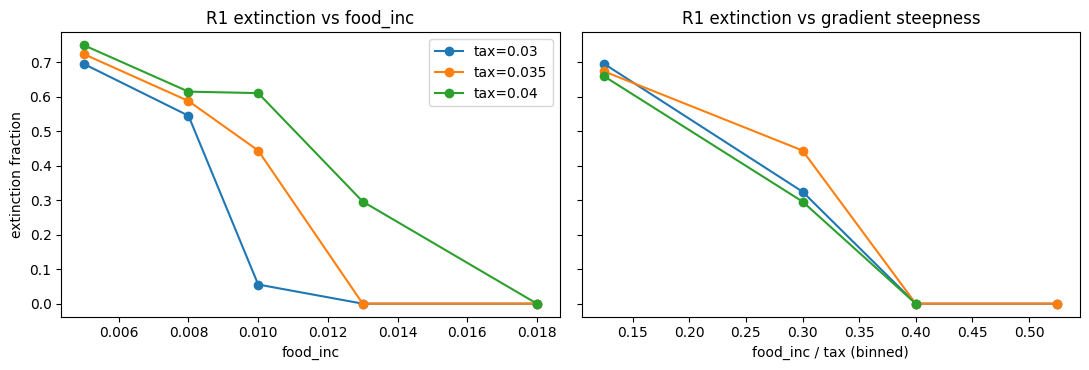

In [4]:
R1['ratio'] = R1.param_food_inc / R1.param_tax
ext_tab = R1.groupby(['param_tax', 'param_food_inc']).extinct.mean().unstack()
print(f"{len(R1)} rows, {int(R1.extinct.sum())} extinct ({R1.extinct.mean():.0%})")
print("extinction fraction by (tax, food_inc), all m_scale pooled:")
display(ext_tab.round(2))

def auc(score, y):   # P(score ranks an extinct run above a viable one), 0.5 = no information
    from scipy.stats import rankdata
    rk = rankdata(score); n1 = y.sum(); n0 = len(y) - n1
    return (rk[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
y = R1.extinct.values.astype(bool)
print(f"AUC for predicting extinction: by -food_inc {auc(-R1.param_food_inc.values, y):.3f}, "
      f"by -food_inc/tax {auc(-R1.ratio.values, y):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for tx, g in R1.groupby('param_tax'):
    e = g.groupby('param_food_inc').extinct.mean()
    ax[0].plot(e.index, e.values, 'o-', label=f'tax={tx:g}')
    gb = g.assign(rb=pd.cut(g.ratio, [0, .25, .35, .45, .6, 1])).groupby('rb', observed=True)
    ax[1].plot([iv.mid for iv in gb.extinct.mean().index], gb.extinct.mean().values, 'o-', label=f'tax={tx:g}')
ax[0].set_xlabel('food_inc'); ax[1].set_xlabel('food_inc / tax (binned)')
ax[0].set_ylabel('extinction fraction'); ax[0].legend(); ax[0].set_title('R1 extinction vs food_inc')
ax[1].set_title('R1 extinction vs gradient steepness')
fig.tight_layout(); plt.show()

### Example runs: a starved, an intermediate and a rich `food_inc` (with the L1 dissipation probes)

R1 never had a dissipation readout, so everything below is **new, observed in these example runs, not a
campaign result**. Config: R1 row `config_idx=208` loaded through the public recipe path
(`evoca_from_scan` then `import_run`): `m_scale` 3.5, `tax` 0.035, `gdiff` 0.08, `mu_lut` 0.03,
`mu_egene` = `mu_egenome` = 0.003, `restricted_mu` on, `tax_per_egene` 0.0008 (at its recorded
`food_inc` 0.018 this row was viable). Only `food_inc` is changed: **0.010 starved**, **0.016
intermediate** (inside R1's productive window), **0.050 rich** (beyond anything R1 sampled). N=128, 3000
steps, seed 0. Plots: alive population; per-capita throughput Phi (= `diss_step / alive`); dissipation
breakdown per step, stacked (tax, death of evicted cells, overflow past the F=1 cap) with mouthful intake
overlaid; and the env-food field (colormode 1) at t=200 and t=3000.

In [5]:
EX = {'starved': 0.010, 'intermediate': 0.016, 'rich': 0.050}
ex_series, ex_shots, ex_resid = {}, {}, {}
t0 = time.time()
for name, fi in EX.items():
    sim, _ = r1_sim(208, N=128, seed=0, food_inc=fi)
    ex_series[name], ex_shots[name], ex_resid[name] = trace(sim, 3000, every=25, snaps=(200, 3000))
    sim.free()
print(f"3 example runs in {time.time()-t0:.0f} s")
print("worst whole-system energy-identity residual |source - d(storage) - diss| per run:",
      {k: f'{v:.2e}' for k, v in ex_resid.items()})

3 example runs in 5 s
worst whole-system energy-identity residual |source - d(storage) - diss| per run: {'starved': '2.14e-04', 'intermediate': '4.83e-04', 'rich': '8.54e-04'}


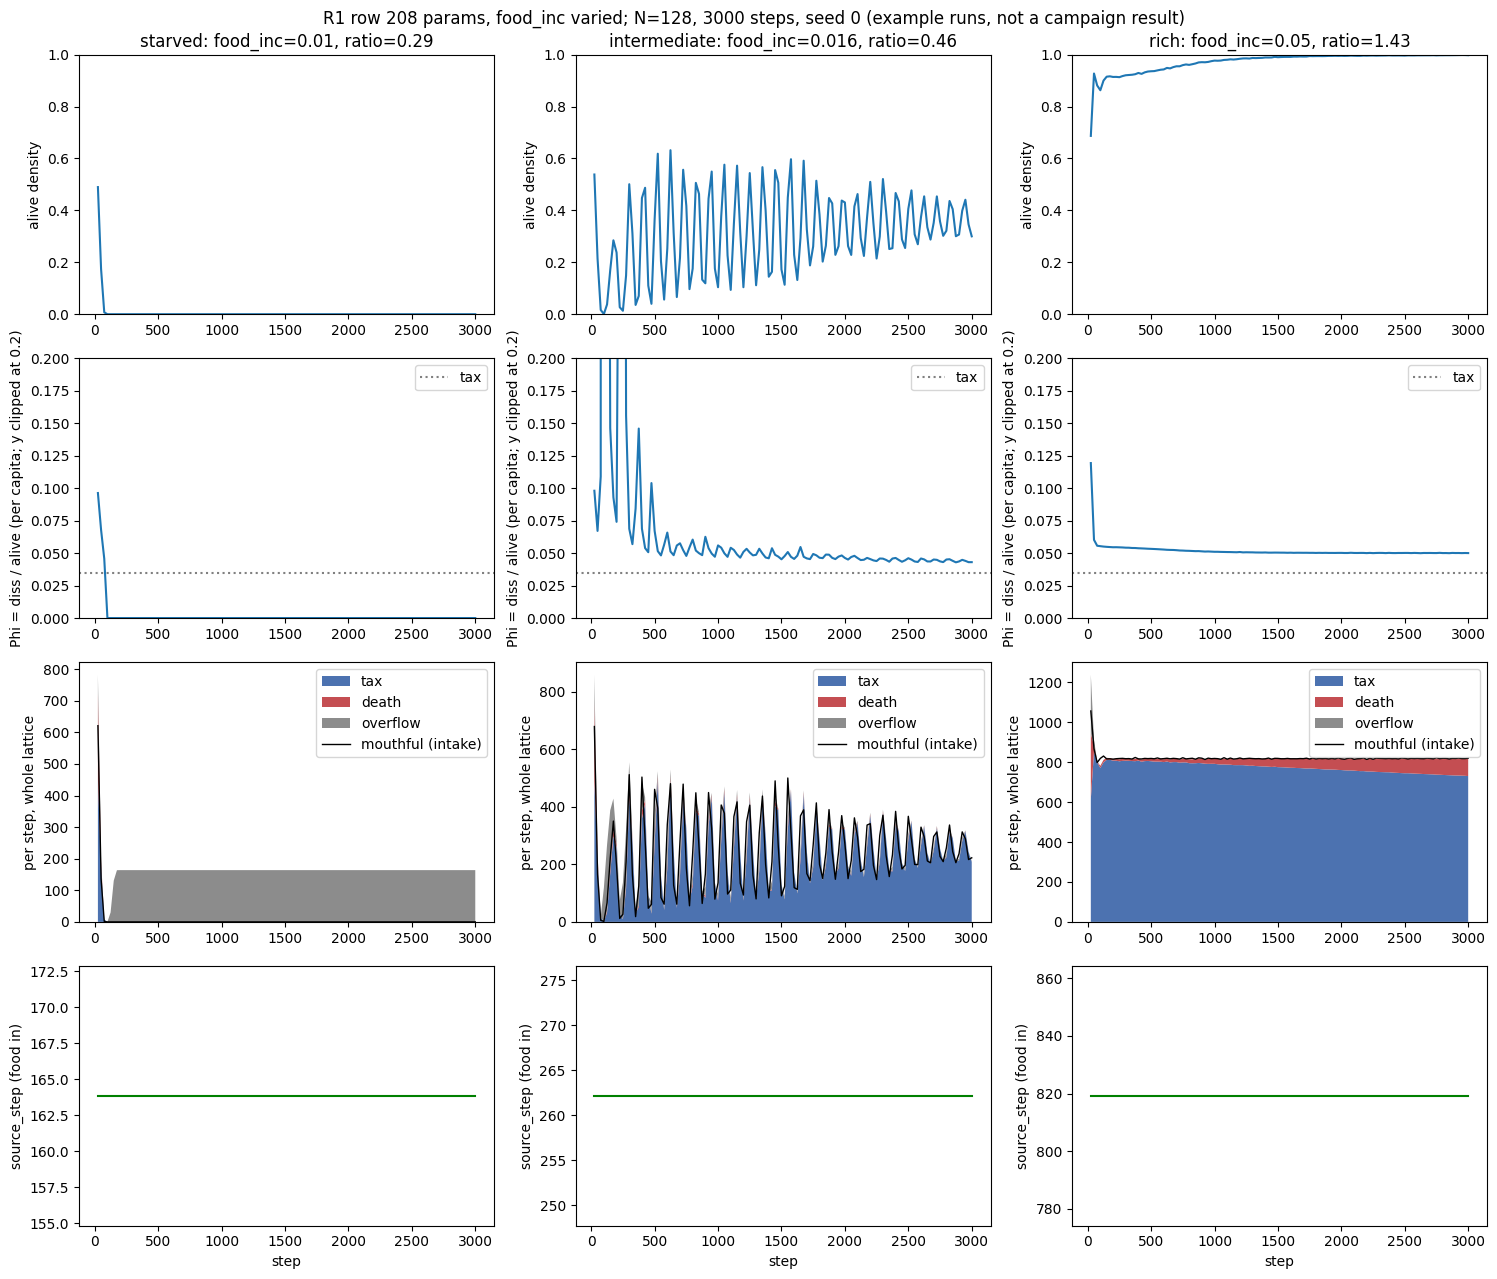

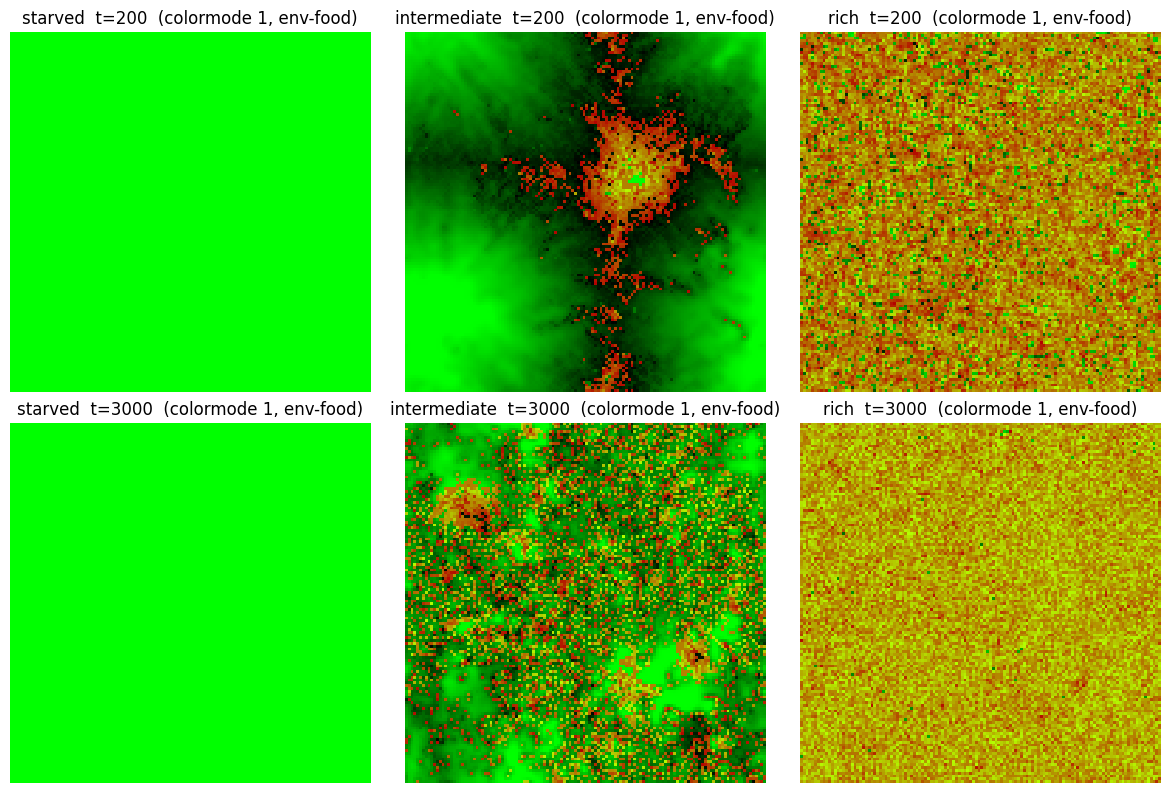

In [6]:
fig, axs = plt.subplots(4, 3, figsize=(15, 13))
for j, (name, fi) in enumerate(EX.items()):
    s = ex_series[name]
    axs[0, j].plot(s.t, s.alive / 128**2); axs[0, j].set_ylim(0, 1)
    axs[0, j].set_title(f'{name}: food_inc={fi}, ratio={fi/0.035:.2f}'); axs[0, j].set_ylabel('alive density')
    axs[1, j].plot(s.t, s.phi); axs[1, j].set_ylim(0, 0.2); axs[1, j].set_ylabel('Phi = diss / alive (per capita; y clipped at 0.2)')
    axs[1, j].axhline(0.035, color='gray', ls=':', label='tax'); axs[1, j].legend(loc='upper right')
    axs[2, j].stackplot(s.t, s.tax, s.death, s.overflow, labels=['tax', 'death', 'overflow'],
                        colors=['#4c72b0', '#c44e52', '#8c8c8c'])
    axs[2, j].plot(s.t, s.mouthful, 'k-', lw=1, label='mouthful (intake)')
    axs[2, j].set_ylabel('per step, whole lattice'); axs[2, j].legend(loc='upper right')
    axs[3, j].plot(s.t, s.source, color='green'); axs[3, j].set_ylabel('source_step (food in)')
    axs[3, j].set_xlabel('step')
fig.suptitle('R1 row 208 params, food_inc varied; N=128, 3000 steps, seed 0 (example runs, not a campaign result)')
fig.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for j, name in enumerate(EX):
    for i, t in enumerate((200, 3000)):
        axs[i, j].imshow(ex_shots[name][t], interpolation='nearest'); axs[i, j].axis('off')
        axs[i, j].set_title(f'{name}  t={t}  (colormode 1, env-food)')
fig.tight_layout(); plt.show()

In [7]:
rows = []
for name, s in ex_series.items():
    late = s[s.t > 2000]
    rows.append(dict(run=name, food_inc=EX[name], ratio=round(EX[name] / 0.035, 2),
                     alive_final=int(s.alive.iloc[-1]), density_final=round(s.alive.iloc[-1] / 128**2, 3),
                     phi_late=round(late.phi.mean(), 4), tax_late=round(late.tax.mean(), 1),
                     death_late=round(late.death.mean(), 1), overflow_late=round(late.overflow.mean(), 1),
                     mouthful_late=round(late.mouthful.mean(), 1),
                     source_late=round(late.source.mean(), 1)))
display(pd.DataFrame(rows).set_index('run'))

,food_inc,ratio,alive_final,density_final,phi_late,tax_late,death_late,overflow_late,mouthful_late,source_late
run,,,,,,,,,,
starved,0.010,0.29,0,0.000,0.0000,0.0,0.0,163.8,0.0,163.8
intermediate,0.016,0.46,4915,0.300,0.0447,252.0,2.0,5.6,254.3,262.1
rich,0.050,1.43,16347,0.998,0.0501,745.3,73.2,0.0,818.8,819.2


### Sanity check against the recorded R1 rows

Same recipe path, N=128 and 3000 steps versus the recorded N=256, 8000 steps (so only broad agreement is
expected): row 208 (`food_inc` 0.018) was recorded viable at density 0.433; row 45 (`food_inc` 0.005,
`m_scale` 3.5) was recorded extinct.

In [8]:
chk = []
for idx in (208, 45):
    rec = R1[R1.config_idx == idx].iloc[0]
    sim, _ = r1_sim(idx, N=128, seed=0)
    for _ in range(3000): sim.step()
    alive = sim.get_dissipation()['alive']
    chk.append(dict(config_idx=idx, food_inc=rec.param_food_inc,
                    recorded_density_N256_8000=round(rec.alive_density_final, 3), recorded_extinct=bool(rec.extinct),
                    here_density_N128_3000=round(alive / 128**2, 3), here_extinct_at_end=(alive == 0)))
    sim.free()
display(pd.DataFrame(chk).set_index('config_idx'))

,food_inc,recorded_density_N256_8000,recorded_extinct,here_density_N128_3000,here_extinct_at_end
config_idx,,,,,
208,0.018,0.433,False,0.417,False
45,0.005,0.000,True,0.000,True


**Observations (OBS-R1, all "observed in these example runs, N=128, seed 0, not a campaign result"):**
see the executed outputs above. The cell below states them from the numbers rather than from memory.

In [9]:
s = ex_series
late = lambda n: s[n][s[n].t > 2000]
print("starved      : final alive =", int(s['starved'].alive.iloc[-1]),
      "| extinct at t =", (int(s['starved'][s['starved'].alive == 0].t.iloc[0]) if (s['starved'].alive == 0).any() else 'never'))
print(f"intermediate : late Phi={late('intermediate').phi.mean():.3f} (tax=0.035), late overflow/step={late('intermediate').overflow.mean():.1f}, "
      f"late tax/step={late('intermediate').tax.mean():.1f}")
print(f"rich         : late Phi={late('rich').phi.mean():.3f}, late overflow/step={late('rich').overflow.mean():.1f}, "
      f"late tax/step={late('rich').tax.mean():.1f}, late alive density={late('rich').alive.mean()/128**2:.3f}")
frac = lambda n: late(n).overflow.mean() / max(late(n).source.mean(), 1e-12)
print(f"fraction of food input lost to overflow (late): intermediate {frac('intermediate'):.2f}, rich {frac('rich'):.2f}")

starved      : final alive = 0 | extinct at t = 100
intermediate : late Phi=0.045 (tax=0.035), late overflow/step=5.6, late tax/step=252.0
rich         : late Phi=0.050, late overflow/step=0.0, late tax/step=745.3, late alive density=0.997
fraction of food input lost to overflow (late): intermediate 0.02, rich 0.00


Reading the executed figures (observed in these example runs, N=128, seed 0, **not a campaign result**; the
colormode-1 legend was not verified from source, so colors are described, not decoded beyond "bright green is
the fully replenished field"):

- **Starved (ratio 0.29):** the population collapses within the first 100 steps. Afterwards *all* of the
  source (about 164 per step) is lost to overflow, because nobody eats, and Phi is 0 by definition
  (`alive = 0`) even though the system is still dissipating. The env-food field sits at the cap everywhere
  (uniform bright green).
- **Intermediate (ratio 0.46):** the population does not settle. Density swings between roughly 0.1 and 0.6
  in boom/bust cycles with a period of a few dozen steps (window-averaged at 25 steps, so the period is not
  resolved), and slowly damps. Tax is the dominant sink, overflow is about 2% of input, and Phi spikes during
  the early bottleneck (to about 20, off the clipped axis) before settling near the tax. It is the only one of
  the three with persistent spatial structure in the env-food field (dark depleted craters and bright
  recovered patches at both t=200 and t=3000), which is the self-generated depletion structure that
  checkpoint section C argued evolution can work on.
- **Rich (ratio 1.43):** the lattice fills (density 0.998), intake equals source (about 819 per step),
  nothing overflows, and the sinks are tax (745) plus death of evicted cells (73). Phi settles at 0.050, which
  is exactly `food_inc`. The env-food field is near-uniform (speckled yellow-orange), i.e. little spatial
  substrate.
- **Energy identity:** the whole-system residual |source - d(storage) - diss| stays below 1e-3 per step in
  all three runs (float32 accumulation), so the L1 accountant closes.
- This single-`m_scale` triple reproduces the *qualitative* ordering (extinct, then viable, then saturated); it
  says nothing yet about where adaptive activity peaks (see the pilot at the end).

In [10]:
# Keep one recipe: the intermediate example, loadable for interactive viewing (ts probe + env-food colormode).
sim, _ = r1_sim(208, N=128, seed=0, food_inc=0.016)
rp = sim.export_recipe('R1cfg208_intermediate_fi0p016', probes={'ts': True}, colormode=1, workstream=WS)
sim.free()
print('saved recipe:', Path(rp).relative_to(ROOT), "(load with import_run(<name>, recipe='final'))")

saved recipe: Research/Resource-driving/Runs/2026-10-15_R1cfg208_intermediate_fi0p016.evoca (load with import_run(<name>, recipe='final'))


**Directions from R1** (carried into `ISSUES.md`): widen the `tax` axis well beyond {0.030 to 0.040} and the
`food_inc` axis well above 0.018 so the `food_inc/tax` collapse and the high-resource flank can actually be
tested (R1 never sampled the rich flank, and viability was U-shaped in `m_scale`, so `m_scale` has to be
held fixed); read productive optima through `A_new`, not just `dyn_excess` (see the next section).

---
## Current state and directions (2026-10)

**Where things stand.**
- The inverted-U is a *prediction* (checkpoint section B/L) with partial indirect support: R1 found a
  tight productive `food_inc` window (0.013 to 0.018, viability collapsing below), but R1 never sampled the
  rich flank, so the high-resource half of the U has **not been tested**, and the digest
  `digests/resource-driving-inverted-U.ipynb` is still a skeleton.
- The two instruments that blocked the section-B figure are now on `main` (merged 2026-10-15): the L1
  dissipation accountant (`sim.get_dissipation()`, and `diss_*` / `diss_phi_*` keys in `run_sim`) and
  `A_new` (G1; `a_new_final`, `a_new_slope` in `run_sim`). The figure is newly unblocked.
- Still gated: C1 (`food_per`), C2/L2 (float `env_mask`, spatial gradient niches) and the C3 campaign sit on
  the unmerged Tier-2 branch `resource-driving`, awaiting N's gate. If merged, `food_per` would let a
  sweep hold mean food input fixed while raising the *temporal* variance of the food field (and C2/L2 the
  spatial variance), which is the cleanest test of whether the high flank is rescued by structure rather than
  by abundance. **Not used here.**

### Pilot: Phi and A_new versus `food_inc/tax` (6 points, N=128, 3000 steps, single seed)

> **PILOT. Not a campaign result.** One seed, one `tax`, N=128, 3000 steps, 6 points. Its purpose is to check
> that the instruments produce a sensible curve and to size the real campaign (spec in `ISSUES.md`, item RES-N1).
> The full design (two or more `tax` levels spanning a wide range, replicate seeds, larger N and longer runs,
> several `m_scale`) is **not** run here.

Config: `build_sim` (GoL LUT, egenome 3, halfplane start) with `m_scale` 3.5, `tax` 0.035, `gdiff` 0.08,
`mu_lut` 0.03, `restricted_mu` on, and **`mu_egene` = `mu_egenome` = 0 (LUT-only evolution)**. The egene
mutations are switched off on purpose: the Channon neutral shadow behind `A_new` models LUT bytes only while
the activity hash covers the full genome, so `A_new` (like `excess_pc`) is not well posed when egenes evolve
(see ISSUES item RES-Q3). `food_inc` = 0.0105, 0.014, 0.021, 0.0315, 0.05, 0.10, i.e. `food_inc/tax` =
0.3, 0.4, 0.6, 0.9, 1.43, 2.86. All columns come from the public `run_sim` (`a_new_*`, `dyn_excess_pc_slope`, `n_distinct_genomes_mean`,
and the `diss_*` keys; the Phi and channel values are means over the run's 31 samples, transient included).

In [11]:
PILOT_FI = [0.0105, 0.014, 0.021, 0.0315, 0.05, 0.10]
PILOT_BASE = dict(m_scale=3.5, tax=0.035, gdiff=0.08, mu_lut=0.03, mu_egene=0.0, mu_egenome=0.0,
                  restricted_mu=True, tax_per_egene=0.0)
t0 = time.time(); prow = []
for fi in PILOT_FI:
    m = ee.run_sim({**PILOT_BASE, 'food_inc': fi}, n_steps=3000, sample_every=100, N=128, seed=0, shadow=True)
    prow.append(dict(food_inc=fi, ratio=fi / PILOT_BASE['tax'], extinct=m['extinct'],
                     density_final=m['final_pop'] / 128**2, density_pred=min(1.0, fi / PILOT_BASE['tax']),
                     phi_mean=m['diss_phi_mean'], tax_step=m['diss_tax_step_mean'],
                     death_step=m['diss_death_step_mean'], overflow_step=m['diss_overflow_step_mean'],
                     source_step=m['diss_source_step_mean'],
                     a_new_final=m['a_new_final'], a_new_slope=m['a_new_slope'],
                     dyn_excess_pc_slope=m['dyn_excess_pc_slope'], n_distinct_mean=m['n_distinct_genomes_mean']))
P = pd.DataFrame(prow)
print(f"pilot: 6 points in {time.time()-t0:.0f} s")
display(P.round(4).set_index('food_inc'))

pilot: 6 points in 15 s


,ratio,extinct,density_final,density_pred,phi_mean,tax_step,death_step,overflow_step,source_step,a_new_final,a_new_slope,dyn_excess_pc_slope,n_distinct_mean
food_inc,,,,,,,,,,,,,
0.0105,0.3000,False,0.0013,0.3,0.1107,137.9401,17.0210,8.6706,166.4826,7.0,0.0017,12.1455,3958.8387
0.0140,0.4000,False,0.4029,0.4,0.0341,199.8729,1.6193,0.1381,221.9768,1197.0,0.4342,8.0305,5689.6129
0.0210,0.6000,False,0.6004,0.6,0.0339,335.9026,0.4935,0.0002,332.9652,2145.0,0.6219,8.5176,9495.8065
0.0315,0.9000,False,0.8973,0.9,0.0340,497.4380,2.5673,0.0000,499.4477,1839.0,0.8196,2.2709,13946.6774
0.0500,1.4286,False,1.0000,1.0,0.0488,554.9306,244.4367,0.0051,792.7742,707.0,0.0077,0.7577,15845.2258
0.1000,2.8571,False,1.0000,1.0,0.0966,554.9419,962.9224,64.1443,1585.5484,4.0,0.0000,0.8861,15851.6452


Every column above comes from the public `run_sim` (single source; `phi_mean` and the `*_step` columns are means over
the 31 samples of the run, which include the initial colonization transient). Note one thing learned while building
this: stepping the *same* configuration by hand (`build_sim` plus `sim.step()`, as `trace()` does) is **not**
bit-identical to `run_sim`, because the per-sample activity/shadow updates consume the C random stream. Away from
threshold the two agree to a few percent (for example final population 6511 vs 6601 at ratio 0.4), but at the
near-threshold point (ratio 0.3) the same seed gave 255 cells by hand and 21 inside `run_sim`. That sensitivity is
itself a finding about the threshold (ISSUES item RES-N7), and is why the pilot table is not mixed across entry points.

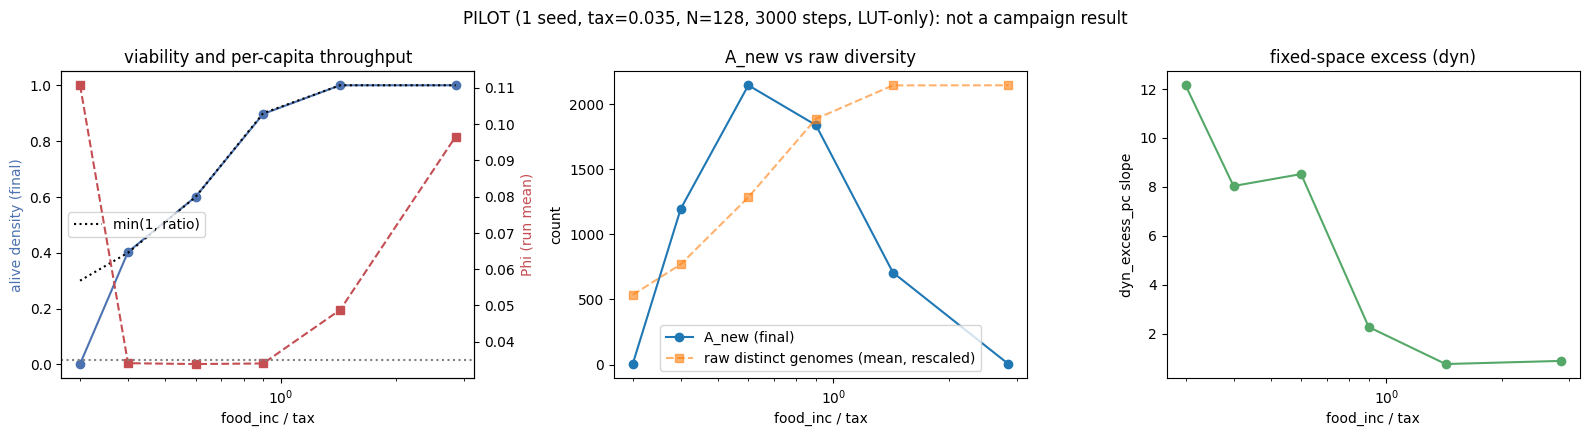

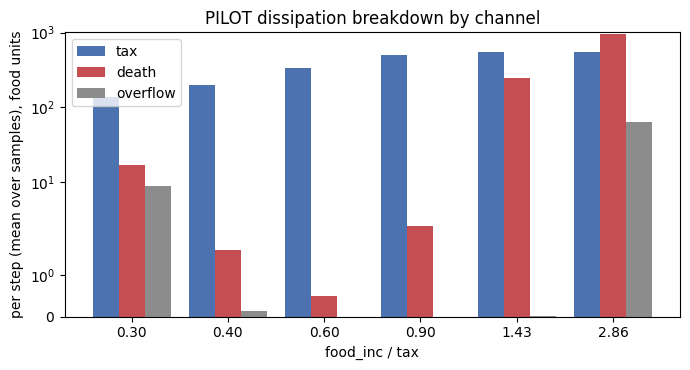

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
x = P.ratio
ax[0].plot(x, P.density_final, 'o-', color='#4c72b0'); ax[0].plot(x, P.density_pred, 'k:', label='min(1, ratio)'); ax[0].legend(loc='center left'); ax[0].set_ylabel('alive density (final)', color='#4c72b0')
a2 = ax[0].twinx(); a2.plot(x, P.phi_mean, 's--', color='#c44e52'); a2.set_ylabel('Phi (run mean)', color='#c44e52')
a2.axhline(PILOT_BASE['tax'], color='gray', ls=':')
ax[0].set_title('viability and per-capita throughput')
ax[1].plot(x, P.a_new_final, 'o-', label='A_new (final)')
ax[1].plot(x, P.n_distinct_mean / P.n_distinct_mean.max() * P.a_new_final.max(), 's--', alpha=.6,
           label='raw distinct genomes (mean, rescaled)')
ax[1].set_ylabel('count'); ax[1].legend(); ax[1].set_title('A_new vs raw diversity')
ax[2].plot(x, P.dyn_excess_pc_slope, 'o-', color='#55a868'); ax[2].set_ylabel('dyn_excess_pc slope')
ax[2].set_title('fixed-space excess (dyn)')
for a in (ax[0], ax[1], ax[2]):
    a.set_xscale('log'); a.set_xlabel('food_inc / tax')
fig.suptitle('PILOT (1 seed, tax=0.035, N=128, 3000 steps, LUT-only): not a campaign result')
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
b = np.arange(len(P)); w = .27
ax.bar(b - w, P.tax_step, w, label='tax', color='#4c72b0'); ax.bar(b, P.death_step, w, label='death', color='#c44e52')
ax.bar(b + w, P.overflow_step, w, label='overflow', color='#8c8c8c')
ax.set_xticks(b); ax.set_xticklabels([f'{r:.2f}' for r in P.ratio]); ax.set_yscale('symlog')
ax.set_xlabel('food_inc / tax'); ax.set_ylabel('per step (mean over samples), food units'); ax.legend()
ax.set_title('PILOT dissipation breakdown by channel'); fig.tight_layout(); plt.show()

**Pilot observations (observed in this pilot, N=128, one seed, not a campaign result).** The next cell prints
the quantitative reading from the executed table so the prose and numbers cannot drift apart.

In [13]:
pk = P.loc[P.a_new_final.idxmax()]; hi = P.iloc[-1]; lo = P.iloc[0]
print(f"A_new peaks at food_inc/tax = {pk.ratio:.2f} (A_new={pk.a_new_final:.0f}); dyn_excess_pc slope peaks at "
      f"{P.loc[P.dyn_excess_pc_slope.idxmax()].ratio:.2f} ({P.dyn_excess_pc_slope.max():.1f}) but at a population of {int(lo.density_final*128**2)} cells there.")
print(f"richest point (ratio {hi.ratio:.2f}): density {hi.density_final:.2f}, raw distinct genomes {hi.n_distinct_mean:.0f}, A_new {hi.a_new_final:.0f}, Phi {hi.phi_mean:.3f}")
print("final density vs min(1, ratio):", list(zip(P.ratio.round(2), P.density_final.round(3), P.density_pred.round(3))))
print("Phi (run mean) vs max(tax, food_inc):", list(zip(P.phi_mean.round(3), np.maximum(0.035, P.food_inc).round(3))))

A_new peaks at food_inc/tax = 0.60 (A_new=2145); dyn_excess_pc slope peaks at 0.30 (12.1) but at a population of 21 cells there.
richest point (ratio 2.86): density 1.00, raw distinct genomes 15852, A_new 4, Phi 0.097
final density vs min(1, ratio): [(0.3, 0.001, 0.3), (0.4, 0.403, 0.4), (0.6, 0.6, 0.6), (0.9, 0.897, 0.9), (1.43, 1.0, 1.0), (2.86, 1.0, 1.0)]
Phi (run mean) vs max(tax, food_inc): [(0.111, 0.035), (0.034, 0.035), (0.034, 0.035), (0.034, 0.035), (0.049, 0.05), (0.097, 0.1)]


**Reading, and what it does not show.**
- **A mass-balance identity the pilot makes visible.** For ratio < 1 the final alive density equals
  `food_inc / tax` almost exactly (0.403, 0.600, 0.897 against 0.4, 0.6, 0.9), and above ratio 1 the lattice is
  full. That is the L1 energy identity at quasi-steady state: when nothing overflows and death is rare, food in
  (`food_inc` per cell) equals tax paid (`tax` per alive cell), so occupancy settles at `food_inc/tax`. The ratio
  is therefore not just "gradient steepness"; below 1 it *is* the carrying occupancy. Consequently the rising
  flank of any activity-vs-ratio curve is confounded with population size (more cells, more genomes), and
  excess/`A_new` must be judged per capita or against a population-matched neutral baseline before calling it
  adaptive.
- **Phi is nearly degenerate as an x-axis.** Per-capita throughput Phi = source / alive at steady state, so
  Phi = max(`tax`, `food_inc`): flat at about 0.034 (the tax) across the whole food-limited interior, and equal to
  `food_inc` once the lattice is full (0.049 and 0.097 at the two richest points; the 0.111 at ratio 0.3 is the
  collapsing near-extinct run, not a steady state). Phi therefore separates only the rich flank, where the
  dissipation is carried first by death of evicted cells (ratio 1.43) and then by overflow (ratio 2.86). Whether
  Phi carries information beyond `food_inc/tax` anywhere in this model is open (ISSUES RES-Q2); it is
  informative as an accounting check, not (here) as an independent axis.
- **Raw versus excess (checkpoint section B), first look.** The raw distinct-genome count rises with food input and
  saturates at the full lattice (15852), while `A_new` rises, peaks in the interior (2145 at ratio 0.6) and
  collapses to 4 at ratio 2.86. That is the predicted divergence, in one seed, but see the occupancy confound
  above, and the cognitive/egene axis is off.
- The fixed-space `dyn_excess_pc` slope is largest at the near-extinct ratio 0.3 point, where only 21 cells are
  alive; a per-component average over a handful of cells is not a trustworthy signal, so it is not read as a peak.
- Caveats: one seed and one `tax` (so **no collapse test**: the central claim that curves at different `tax`
  superimpose against the ratio is untested), LUT-only evolution (the egene axis, where N's two "exception"
  hypotheses live, is off), N=128 and 3000 steps (activity metrics still growing), and the starved end is a
  sharp, seed-sensitive threshold between ratio 0.3 and 0.4 that a six-point grid cannot resolve.

**Newly unblocked by the 2026-10-15 merges:** the section-B figure (B1) and the Phi x-axis; the adaptive-vs-drift
test H1 can use the lineage return reducer (D2, merged) together with `A_new` on this same sweep.

**Outstanding decisions and directions** are in `ISSUES.md` (shown at the top of this notebook): the Tier-2
`resource-driving` branch gate (RES-D1), the full campaign spec (RES-N1), the egene-aware `A_new`
well-posedness question (RES-Q3), and the `ts` probe lacking Phi (RES-N4).

In [14]:
print(f"notebook wall time: {time.time()-NB_T0:.0f} s")

notebook wall time: 23 s
